In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

## 1. Читання датасету та перемішування записів

In [2]:
df = pd.read_csv('IrisData_full.csv', header=None, sep=',')
df = df.sample(frac=1, random_state=42).reset_index(drop=True)
df.head()

,0,1,2,3,4
0,6.1,2.8,4.7,1.2,Iris-versicolor
1,5.7,3.8,1.7,0.3,Iris-setosa
2,7.7,2.6,6.9,2.3,Iris-virginica
3,6.0,2.9,4.5,1.5,Iris-versicolor
4,6.8,2.8,4.8,1.4,Iris-versicolor


## 2. Нормалізація параметрів (StandardScaler)

In [3]:
X = df.iloc[:, :4].values
y = df.iloc[:, 4].values

le = LabelEncoder()
y_num = le.fit_transform(y)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## 3. Розділення на навчальну та тестову вибірки

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_num, test_size=0.25, random_state=42)
print(X_train.shape, X_test.shape)

(112, 4) (38, 4)


## 4. PCA для візуалізації у 2D

PCA зменшує розмірність даних (4D → 2D) із мінімальною втратою інформації. PCA 1 — напрямок максимальної дисперсії, PCA 2 — напрямок максимальної залишкової дисперсії, ортогональний до PCA 1. Модель KNN навчається на всіх 4 ознаках, а PCA використовується лише для побудови графіків.

In [5]:
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

# Сітка у просторі PCA
x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                     np.linspace(y_min, y_max, 300))

cmap_light = ListedColormap(['#FFDDDD', '#DDFFDD', '#DDDDFF'])
cmap_bold = ['red', 'orange', 'navy']
markers = ['o', '^', '*']

## 5. Навчання KNN з різними K та візуалізація

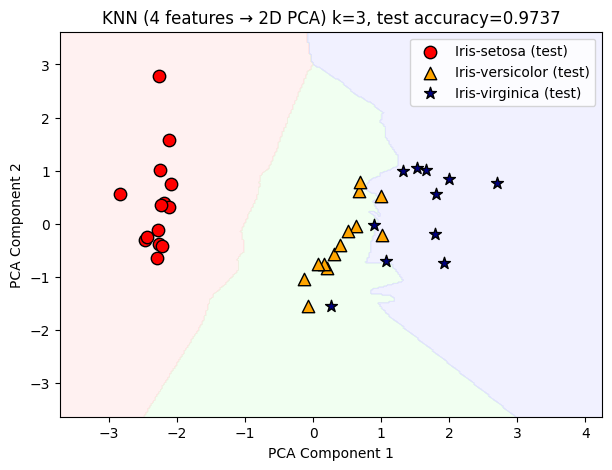

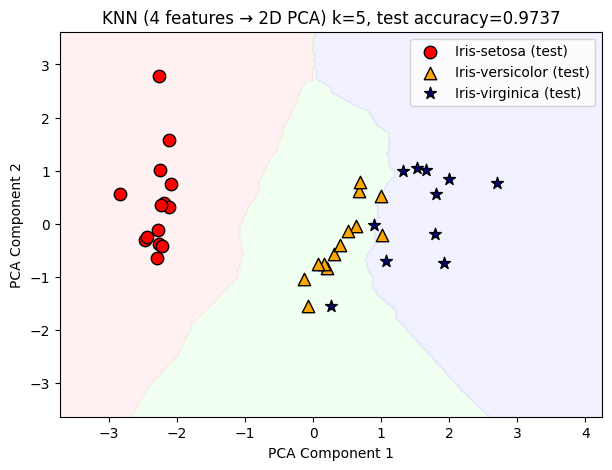

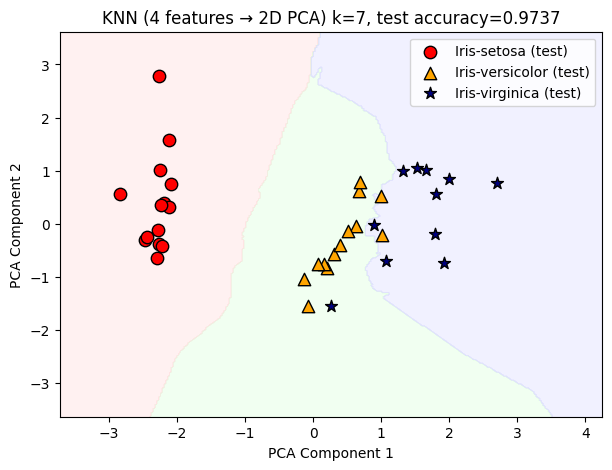

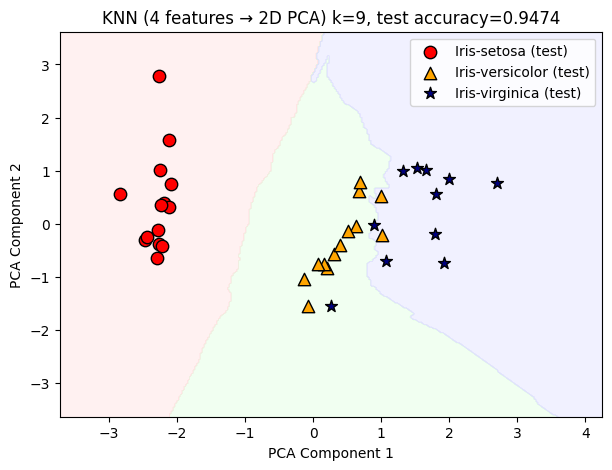

In [6]:
k_list = range(3, 10, 2)
acc_list = []

for k in k_list:
    knn = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    acc_list.append(acc)

    # Передбачення для сітки через інверсію PCA
    grid_points = np.c_[xx.ravel(), yy.ravel()]
    grid_points_4d = pca.inverse_transform(grid_points)
    Z = knn.predict(grid_points_4d)
    Z = Z.reshape(xx.shape)

    # Графік
    plt.figure(figsize=(7, 5))
    plt.contourf(xx, yy, Z, cmap=cmap_light, alpha=0.4)

    for idx, class_num in enumerate(np.unique(y_num)):
        plt.scatter(X_test_pca[y_test == class_num, 0], X_test_pca[y_test == class_num, 1],
                    color=cmap_bold[idx], marker=markers[idx], edgecolor='k', s=80,
                    label=f'{le.inverse_transform([class_num])[0]} (test)')

    plt.title(f'KNN (4 features → 2D PCA) k={k}, test accuracy={acc:.4f}')
    plt.xlabel('PCA Component 1')
    plt.ylabel('PCA Component 2')
    plt.legend()
    plt.show()

## 6. Вибір найкращого K

In [7]:
best_idx = int(np.argmax(acc_list))
best_k = list(k_list)[best_idx]
best_acc = acc_list[best_idx]
print(f"✅ Best k: {best_k} with accuracy: {best_acc:.4f}")

# Навчання моделі з найкращим k
knn_best = KNeighborsClassifier(n_neighbors=best_k, metric='euclidean')
knn_best.fit(X_train, y_train)

# Класифікація нового зразка
new_sample = np.array([[5.1, 3.5, 1.4, 0.2]])
new_pred = knn_best.predict(scaler.transform(new_sample))
print("New sample predicted class:", le.inverse_transform(new_pred)[0])

✅ Best k: 3 with accuracy: 0.9737
New sample predicted class: Iris-setosa
